In [ ]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import explained_variance_score

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
!pip install catboost
from catboost import CatBoostRegressor

import warnings
warnings.filterwarnings(action='ignore')

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.6/98.6 MB 9.9 MB/s eta 0:00:00


In [ ]:
data1 = pd.read_csv('/content/drive/MyDrive/Final year project/Vegetable_market.csv')
data=data1.copy()

In [ ]:
data.head(100)

,Vegetable,Season,Month,Temp,Deasaster Happen in last 3month,Vegetable condition,Price per kg
0,potato,winter,Jan,15,no,fresh,20
1,tomato,winter,Jan,15,no,fresh,50
2,peas,winter,Jan,15,no,fresh,70
3,pumkin,winter,Jan,15,no,fresh,25
4,cucumber,winter,Jan,15,no,fresh,20
...,...,...,...,...,...,...,...
95,califlower,summer,apr,37,no,fresh,55
96,pointed grourd,monsoon,july,30,no,fresh,30
97,potato,monsoon,aug,31,yes,fresh,45
98,peas,monsoon,july,30,yes,fresh,170


In [ ]:
data.info

<bound method DataFrame.info of     Vegetable  Season Month  Temp Deasaster Happen in last 3month  \
0      potato  winter   Jan    15                              no   
1     tomato   winter   Jan    15                              no   
2        peas  winter   Jan    15                              no   
3      pumkin  winter   Jan    15                              no   
4    cucumber  winter   Jan    15                              no   
..        ...     ...   ...   ...                             ...   
116   brinjal  winter   Jan    15                             yes   
117    ginger  winter   Jan    15                              no   
118    potato  summer   apr    32                              no   
119      peas  summer   apr    33                              no   
120    radish  summer   apr    32                              no   

    Vegetable condition  Price per kg  
0                 fresh            20  
1                 fresh            50  
2                 f

In [ ]:
data.isnull().sum()

Vegetable                          0
Season                             0
Month                              0
Temp                               0
Deasaster Happen in last 3month    0
Vegetable condition                0
Price per kg                       0
dtype: int64

In [ ]:
from sklearn.preprocessing import LabelEncoder
var = LabelEncoder()
data['Vegetable']=var.fit_transform(data['Vegetable']) 
data['Season']=var.fit_transform(data['Season']) 
data['Month']=var.fit_transform(data['Month']) 
data['Deasaster Happen in last 3month']=var.fit_transform(data['Deasaster Happen in last 3month']) 
data['Vegetable condition']=var.fit_transform(data['Vegetable condition']) 

In [ ]:
data

,Vegetable,Season,Month,Temp,Deasaster Happen in last 3month,Vegetable condition,Price per kg
0,13,4,0,15,0,1,20
1,16,4,0,15,0,1,50
2,11,4,0,15,0,1,70
3,14,4,0,15,0,1,25
4,6,4,0,15,0,1,20
...,...,...,...,...,...,...,...
116,2,4,0,15,1,1,33
117,8,4,0,15,0,1,88
118,13,3,1,32,0,1,24
119,11,3,1,33,0,1,33


In [ ]:
X=data[['Vegetable','Season','Month','Temp','Deasaster Happen in last 3month','Vegetable condition']]
Y=data['Price per kg']
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.1)

In [ ]:
y_train.shape

(108,)

In [ ]:
models = {
    "                     Linear Regression": LinearRegression(),
    " Linear Regression (L2 Regularization)": Ridge(),
    " Linear Regression (L1 Regularization)": Lasso(),
    "                   K-Nearest Neighbors": KNeighborsRegressor(),
    "                         Decision Tree": DecisionTreeRegressor(),
    "                         Random Forest": RandomForestRegressor(),
    "                     Gradient Boosting": GradientBoostingRegressor(),
    "                               XGBoost": XGBRegressor(),
    "                              LightGBM": LGBMRegressor(),
    "                              CatBoost": CatBoostRegressor(verbose=0)
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name + " trained.")

                     Linear Regression trained.
 Linear Regression (L2 Regularization) trained.
 Linear Regression (L1 Regularization) trained.
                   K-Nearest Neighbors trained.
                         Decision Tree trained.
                         Random Forest trained.
                     Gradient Boosting trained.
                               XGBoost trained.
                              LightGBM trained.
                              CatBoost trained.


In [ ]:
for name, model in models.items():
    print(name + " R^2 Score: {:.5f}".format(model.score(X_test, y_test)))
    

                     Linear Regression R^2 Score: 0.28686
 Linear Regression (L2 Regularization) R^2 Score: 0.26770
 Linear Regression (L1 Regularization) R^2 Score: 0.22649
                   K-Nearest Neighbors R^2 Score: 0.39205
                         Decision Tree R^2 Score: 0.82083
                         Random Forest R^2 Score: 0.72565
                     Gradient Boosting R^2 Score: 0.74866
                               XGBoost R^2 Score: 0.81981
                              LightGBM R^2 Score: 0.69431
                              CatBoost R^2 Score: 0.81323


In [ ]:

model=RandomForestRegressor(n_estimators=90,max_depth=8)
model.fit(X_train, y_train)
accuracy = model.score(X_test, y_test)
print(accuracy)
import joblib
#joblib.dump(model,'Price_model1.joblib')

0.8155000531937706


In [ ]:

y_pred = model.predict(X_test)

# Calculate the explained variance score
evs = explained_variance_score(y_test, y_pred)

print('Explained variance score:', evs)

Explained variance score: 0.8155199735985837


In [ ]:
y_all = model.predict(X)

In [ ]:
evs = explained_variance_score(y_all,Y)
evs

0.8733473735961668

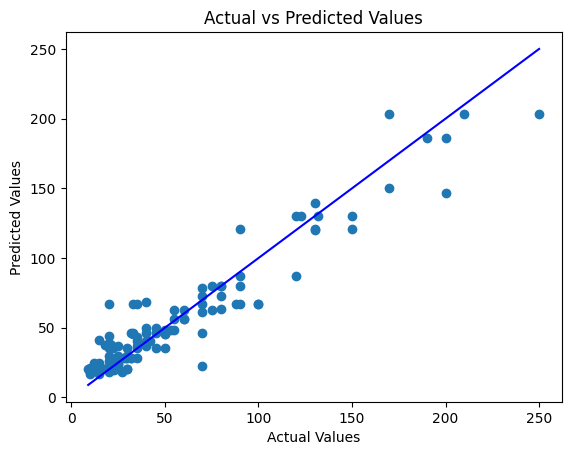

In [ ]:
import matplotlib.pyplot as plt
plt.scatter(Y,y_all)
p1 = max(max(y_all), max(Y))
p2 = min(min(y_all), min(Y))
plt.plot([p1, p2], [p1, p2], 'b-')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs Predicted Values')
plt.savefig('avsp.png')

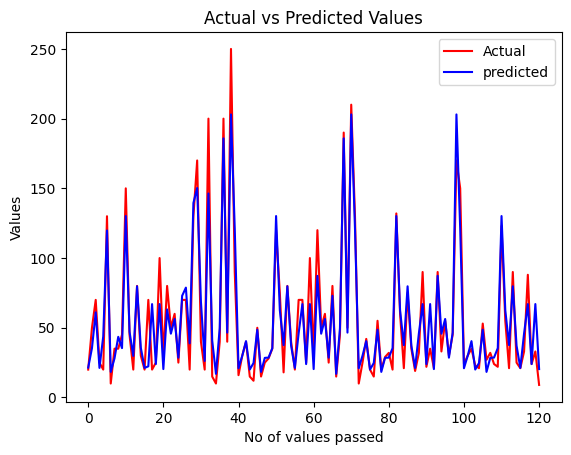

In [ ]:
plt.plot(Y,color = 'red',label='Actual')
plt.plot(y_all,color = 'blue',label='predicted')
plt.xlabel('No of values passed')
plt.ylabel('Values')
plt.title('Actual vs Predicted Values')
plt.legend()
plt.savefig('avsp1.png')

In [ ]:
crop_names_unique=data1.Vegetable.unique()
print(len(crop_names_unique))
a=list(crop_names_unique)
a.sort()
Season=data1.Season.unique()
print(len(Season))
b=list(Season)
b.sort()
Mon=data1.Month.unique()
print(len(Mon))
c=list(Mon)
c.sort()
Condition=data1['Vegetable condition'].unique()
print(len(Condition))
d=list(Condition)
d.sort()



17
5
10
3


In [ ]:
c

['Jan', 'apr', 'aug', 'dec', 'july', 'june', 'march', 'may', 'oct', 'sept']

In [ ]:
vegetables=['Bitter gourd','Raddish','brinjal','cabage','califlower','chilly','cucumber','garlic','ginger','okra','onion','peas','pointed grourd ','potato',
 'pumkin','radish','tomato']
season=['autumn', 'monsoon', 'spring', 'summer', 'winter']
month=['Jan','apr','aug','dec','july','june','march','may','oct','sept']
condition=['avarage', 'fresh', 'scarp']

In [ ]:
veg= 'garlic'
sea = 'spring'
mon='Jan'
con='fresh'
Disaster='no'
Temp=31


In [ ]:
input=[]
for i in range(0,len(vegetables)):
  if vegetables[i]==veg:
    input.append(i)
for i in range(0,len(season)):
  if season[i]==sea:
    input.append(i)
for i in range(0,len(month)):
  if month[i]==mon:
    input.append(i)
input.append(Temp)
if Disaster == 'yes':
  input.append(1)
else:
  input.append(0)
for i in range(0,len(condition)):
  if condition[i]==con:
    input.append(i)

In [ ]:
input=[input]
input

[[7, 2, 0, 31, 0, 1]]

In [ ]:
df=pd.DataFrame(input)

In [ ]:
result=model.predict(df)
result

array([117.41333333])

In [ ]:
a=int(result)
a

117

In [ ]:
print("per kg price of "+ veg+ " is "+ str(a))

per kg price of garlic is 117
